c:\Users\Natck\AppData\Local\Programs\Python\Python313\Lib\site-packages\yfinance\scrapers\history.py:173: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()
c:\Users\Natck\AppData\Local\Programs\Python\Python313\Lib\site-packages\yfinance\scrapers\history.py:173: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()
c:\Users\Natck\AppData\Local\Programs\Python\Python313\Lib\site-packages\yfinance\scrapers\history.py:173: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()
c:\Users\Natck\AppData\Local\Programs\Python\Python313\Lib\site-packages\yfinance\scrapers\history.py:173: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('

Annualized Volatility:
 Ticker
AAPL    0.278626
COST    0.225157
MSFT    0.257143
NVDA    0.522247
TGT     0.351846
WMT     0.208795
dtype: float64


Annualized Return 
 Ticker
AAPL    0.193226
COST    0.201265
MSFT    0.201725
NVDA    0.669495
TGT    -0.028520
WMT     0.201316
dtype: float64


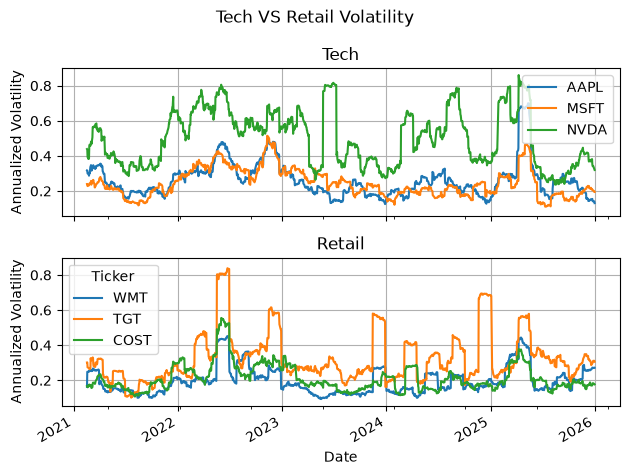

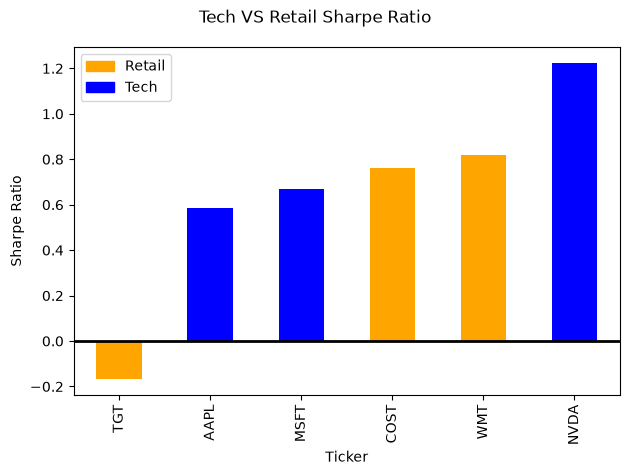

In [9]:
import pandas as pd         
import yfinance as yf
import numpy as np  
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

data = yf.download(["AAPL", "MSFT", "NVDA", "WMT", "TGT", "COST"], start="2021-01-01", end="2026-01-01")
close_prices = data["Close"]
returns = close_prices.pct_change().dropna()

annual_returns = returns.mean() * 252
annual_volatility = returns.std() * 252 **0.5


# Rolling Volatility = STD * sqr(252)
rolling_volatility = returns.rolling(window=30).std() * 252 **0.5
# print(rolling_volatility)

sharpe = (annual_returns - 0.03)/annual_volatility

# Line graph
figure, axes = plt.subplots(2,1,sharex=True, sharey=True)

rolling_volatility[["AAPL", "MSFT", "NVDA"]].plot(ax=axes[0])
rolling_volatility[["WMT", "TGT", "COST"]].plot(ax=axes[1])

figure.suptitle("Tech VS Retail Volatility")

axes[0].set_title("Tech")
axes[0].set_ylabel("Annualized Volatility")
axes[0].grid(True)
axes[0].legend(loc="upper right")

axes[1].set_title("Retail")
axes[1].set_ylabel("Annualized Volatility")
axes[1].grid(True)

# Bar graph
figure2, ax = plt.subplots()

sharpe.sort_values().plot(kind="bar",ax=ax,color=["orange", "blue", "blue", "orange", "orange", "blue"])
ax.axhline(0, color="black", linewidth=2)
ax.legend(handles=[Patch(color="orange", label="Retail"), Patch(color="blue", label="Tech")])

ax.set_ylabel("Sharpe Ratio")
figure2.suptitle("Tech VS Retail Sharpe Ratio")

figure.tight_layout()
figure2.tight_layout()

print(f"Annualized Volatility:\n {annual_volatility}\n\n")
print(f"Annualized Return \n {annual_returns}")
plt.show()
figure.savefig("./../outputs/rolling_volatility.png", dpi=150, bbox_inches="tight")
figure2.savefig("./../outputs/sharpe_ratio.png", dpi=150, bbox_inches="tight")



# Conclusion
The stock with the best Sharpe ratio was NVIDIA. Overall, retail sector had lower volatility led by Walmart (21%) and Costco (23%) volatility. Target was the only outlier having a 35% volatility. During the beginning of 2025, all 6 stocks' volatility spiked upwards showing a market wide trend meaning that owning either sector did not protect investors from high volatility in the beginning of 2025. The tech sector had an overall higher Sharpe ratio than retail. However, this conclusion is limited since only 3 stocks represented each sector. The average Sharpe ratio of the tech sector was largely driven by NVIDIA indicating the requirement of larger sample sizes to more accurately determine the sector performance of tech and retail industry.